**Navigation** : [Version Python](Z3-20-Machine-de-Goedel-Python.ipynb) | [Index Z3](README.md) | [19 - Optimisation](Z3-19-Optimization-Lexicographic-Python.ipynb)

# Z3-CSharp 20 — La machine de Gödel : se réécrire seulement sur preuve

**Objectifs** : prouver une réécriture par réfutation, comparer à la recherche future, mesurer le prix des axiomes et du temps de preuve. **Prérequis** : bases Z3 et optimisation. **Durée** : 90 minutes.

**Source pédagogique primaire** : [le notebook Python de ce même chapitre](Z3-20-Machine-de-Goedel-Python.ipynb), versionné avec cette paire. Ce port reprend son modèle fini, ses calculs, figures et exercices. Le contexte historique et ses références restent dans le Python ; ce carnet ne prétend ni vérifier ces publications ni reproduire une recherche universelle.

Le modèle autorise une bascule seulement après preuve d'amélioration sur sa continuation calculée. Cette propriété se vérifie ici pour la liste finie des candidats ; aucune optimalité universelle n'est attribuée à ce jouet.


In [2]:
// Binding NuGet de Microsoft.Z3, puis chargeur natif : la librairie embarque son binaire par OS.
#r "nuget: Microsoft.Z3, 4.12.2"
#load "Z3NativeLoader.cs"
using System;
using System.Linq;
using System.Collections.Generic;
using System.Globalization;
using System.Text;
using Microsoft.Z3;
Z3NativeLoader.Register(typeof(Context).Assembly);
// Culture invariante : les nombres gardent leurs points decimaux, quelle que soit la machine.
CultureInfo.CurrentCulture = CultureInfo.InvariantCulture;
// Bandeau d'environnement : moteur .NET, version du binding et du solveur natif charges.
Console.WriteLine($".NET {Environment.Version} ; binding Microsoft.Z3 4.12.2 ; natif {Microsoft.Z3.Version.FullVersion}");

Installing Packages Microsoft.Z3

.NET 10.0.13 ; binding Microsoft.Z3 4.12.2 ; natif Z3 4.12.2.0


## 1. Le monde du levier
A rapporte r par pas. B rapporte q après w pas sans récompense. Les axiomes `base` imposent r ∈ [1,2], q ∈ [1,4], w ∈ [0,30] ; `savoir` ajoute q ≥ r+1 et réduit w à 20. La politique initiale calibre pendant 50 pas puis presse A.

In [3]:
// Environnement : rendement r par pas, qualite q du canal B, latence w d'acces au savoir.
record Env(double R, double Q, double W);
// Un plan = suite de segments (depart, politique) ; le journal garde chaque tentative de preuve.
record Segment(int Start, string Policy);
record Proof(string Verdict, string Counterexample, uint Cost);
record Attempt(int T, string Candidate, Proof Proof);
record Run(List<Segment> Plan, List<Attempt> Journal);
// Cout fixe du calibrage : 50 pas de collecte avant que le rendement r ne s'applique.
const int Calibrage = 50;
// Environnement reel, inconnu de la machine : il ne sert qu'a evaluer les plans a posteriori.
var reel = new Env(1.5, 3, 10);
Console.WriteLine("base : r=[1,2], q=[1,4], w=[0,30] ; savoir : w=[0,20], q>=r+1");
Console.WriteLine("Initiale : 50 pas de calibrage, puis A");

base : r=[1,2], q=[1,4], w=[0,30] ; savoir : w=[0,20], q>=r+1


Initiale : 50 pas de calibrage, puis A


## 2. Prouver par réfutation
Chaque preuve utilise un contexte neuf. `UNSAT` prouve l'inégalité pour tous les environnements admissibles, `SAT` fournit un contre-exemple et `UNKNOWN` ne permet pas de basculer. Les termes contiennent notamment le produit q × (D−w) : il s'agit d'arithmétique réelle polynomiale, pas uniquement linéaire.

In [4]:
// Litteral rationnel Z3 construit depuis un double, sans arrondi de format (culture invariante).
ArithExpr Num(Context ctx, double x) => ctx.MkReal(x.ToString("0.################", CultureInfo.InvariantCulture));
// Partie positive symbolique : max(x, 0) encode par un ITE dans l'arithmetique du solveur.
ArithExpr Pos(Context ctx, ArithExpr x) => (ArithExpr)ctx.MkITE(ctx.MkGt(x,ctx.MkReal(0)), x, ctx.MkReal(0));
// Utilite symbolique d'une politique sur d pas : calibrage (au-dela du seuil), A (r*d), B (q*max(d-w,0)).
ArithExpr U(Context ctx, string nom, int d, Dictionary<string,ArithExpr> e) {
    var D = ctx.MkReal(d);
    if (nom == "calibrage") return ctx.MkMul(e["r"], Pos(ctx, ctx.MkSub(D,ctx.MkReal(Calibrage))));
    if (nom == "A") return ctx.MkMul(e["r"], D);
    if (nom == "B") return ctx.MkMul(e["q"], Pos(ctx, ctx.MkSub(D,e["w"])));
    throw new ArgumentException(nom);
}
// Prouveur generique : encadre le jeu (base ou savoir), asserte NON(cible) et laisse Z3 trancher.
Proof Prouver(string jeu, Func<Context,Dictionary<string,ArithExpr>,BoolExpr> cible, uint? budget=null, double? ecart=null, int? wMax=null) {
    using var ctx = new Context();
    var e = new Dictionary<string,ArithExpr> { ["r"] = ctx.MkRealConst("r"), ["q"] = ctx.MkRealConst("q"), ["w"] = ctx.MkRealConst("w") };
    using var s = ctx.MkSolver();
    if (budget.HasValue && budget.Value > 0) { var p=ctx.MkParams(); p.Add("rlimit",budget.Value); s.Parameters=p; }
    var r=e["r"]; var q=e["q"]; var w=e["w"];
    s.Assert(ctx.MkGe(r,ctx.MkReal(1)),ctx.MkLe(r,ctx.MkReal(2)),ctx.MkGe(q,ctx.MkReal(1)),ctx.MkLe(q,ctx.MkReal(4)),ctx.MkGe(w,ctx.MkReal(0)),ctx.MkLe(w,ctx.MkReal(wMax ?? (jeu=="savoir"?20:30))));
    var delta=ecart ?? (jeu=="savoir" ? 1.0 : (double?)null);
    if(delta.HasValue) s.Assert(ctx.MkGe(q,ctx.MkAdd(r,Num(ctx,delta.Value))));
    s.Assert(ctx.MkNot(cible(ctx,e)));
    var result=s.Check();
    var stats=s.Statistics; uint count=stats.Keys.Contains("rlimit count") ? stats["rlimit count"].UIntValue : 0;
    // UNSAT = cible prouvee partout ; SAT = contre-exemple concret ; UNKNOWN = budget rlimit epuise.
    if(result==Status.UNSATISFIABLE) return new Proof("PROUVE",null,count);
    if(result==Status.SATISFIABLE) { var model=s.Model; return new Proof("REFUTE",string.Join(", ",e.Select(x=>$"{x.Key}={model.Evaluate(x.Value,true)}")),count); }
    return new Proof("INCONNU",null,count);
}
// Deux preuves fondatrices : A > calibrage sous savoir ; B > A sous base (sans q>=r+1).
var preuveA=Prouver("savoir", (x,e)=>x.MkGt(U(x,"A",195,e), U(x,"calibrage",195,e)));
var preuveB=Prouver("base", (x,e)=>x.MkGt(U(x,"B",195,e), U(x,"A",195,e)));
Console.WriteLine($"A > calibrage : {preuveA.Verdict}, rlimit {preuveA.Cost}");
Console.WriteLine($"B > A sous base : {preuveB.Verdict}, contre-exemple {preuveB.Counterexample}, rlimit {preuveB.Cost}");

A > calibrage : PROUVE, rlimit 310


B > A sous base : REFUTE, contre-exemple r=3/2, q=3/2, w=1, rlimit 737


La première négation est insatisfiable : presser A immédiatement évite le calibrage dans tous les environnements admissibles. Sous `base`, la seconde formule a un contre-exemple : B n'est pas garanti meilleur que A. Les coûts `rlimit` et modèles exacts dépendent de la version de Z3.

## 3. Comparer à la continuation
À chaque tentative la machine dépense `coutPreuve` pas sans récompense. Elle compare la bascule immédiate au plan qu'elle suivrait en poursuivant sa recherche ; la variante gloutonne compare seulement au calibrage. Le calcul anticipé du plan futur n'est pas lui-même facturé dans ce jouet.

In [5]:
// Utilite symbolique d'un plan entier : somme par segment, cumul de calibrage et prefixes compris.
ArithExpr UtilitePlan(Context ctx, List<Segment> plan, int T, Dictionary<string,ArithExpr> e, int depuis=0) {
    ArithExpr total=ctx.MkReal(0); int calibre=0;
    for(int k=0;k<plan.Count;k++) {
        var seg=plan[k]; int fin=k+1<plan.Count?plan[k+1].Start:T;
        int d=fin-seg.Start, prefixe=Math.Clamp(depuis-seg.Start,0,d);
        if(seg.Policy=="preuve") continue;
        if(seg.Policy=="calibrage") {
            int gain= Math.Max(calibre+d-Calibrage,0)-Math.Max(calibre+prefixe-Calibrage,0);
            total=ctx.MkAdd(total,ctx.MkMul(e["r"],ctx.MkReal(gain))); calibre+=d;
        } else total=ctx.MkAdd(total,ctx.MkSub(U(ctx,seg.Policy,d,e),U(ctx,seg.Policy,prefixe,e)));
    }
    return total;
}
// Machine de Godel : a chaque candidat, prouver qu'il bat le reste du plan ; sinon consigner et passer.
Run Machine(string[] candidats, string jeu, int T, int coutPreuve, uint? budget=null, bool glouton=false, double? ecart=null, int? wMax=null) {
    Run Suite(int t,int i) {
        if(i==candidats.Length || t+coutPreuve>=T) return new Run(new(){new Segment(t,"calibrage")},new());
        int t1=t+coutPreuve; var continuer=Suite(t1,i+1); string nom=candidats[i];
        var preuve=Prouver(jeu,(ctx,e)=>ctx.MkGt(U(ctx,nom,T-t1,e),glouton?U(ctx,"calibrage",T-t1,e):UtilitePlan(ctx,continuer.Plan,T,e,t1)),budget,ecart,wMax);
        var entree=new Attempt(t,nom,preuve);
        // Preuve reussie : le plan adopte le candidat ; echec : la tentative reste dans le journal.
        if(preuve.Verdict=="PROUVE") return new Run(new(){new Segment(t,"preuve"),new Segment(t1,nom)},new(){entree});
        var suite=Suite(t1,i+1); suite.Plan.Insert(0,new Segment(t,"preuve")); suite.Journal.Insert(0,entree); return suite;
    }
    return Suite(0,0);
}
// Gain numerique d'un plan sur un environnement donne : la verite de terrain, hors symbolique.
double Gain(List<Segment> plan,int T,Env e) {
    double total=0; int calibre=0;
    for(int k=0;k<plan.Count;k++) { var seg=plan[k]; int fin=k+1<plan.Count?plan[k+1].Start:T; int d=fin-seg.Start;
        if(seg.Policy=="calibrage") { total+=e.R*Math.Max(d-Math.Max(Calibrage-calibre,0),0); calibre+=d; }
        else if(seg.Policy=="A") total+=e.R*d;
        else if(seg.Policy=="B") total+=e.Q*Math.Max(d-e.W,0);
    } return total;
}
// Machine complete contre gloutonne : la gloutonne ne compare qu'au calibrage, jamais a la suite.
foreach(bool glouton in new[]{false,true}) {
 var run=Machine(new[]{"A","B"},"savoir",200,5,glouton:glouton);
 Console.WriteLine(glouton?"Machine gloutonne :":"Machine de Gödel :");
 foreach(var a in run.Journal) Console.WriteLine($"  t={a.T}, {a.Candidate} : {a.Proof.Verdict}, rlimit {a.Proof.Cost}");
 Console.WriteLine($"  plan {string.Join(", ",run.Plan.Select(s=>$"({s.Start},{s.Policy})"))} ; gain réel {Gain(run.Plan,200,reel)}");
}

Machine de Gödel :


  t=0, A : REFUTE, rlimit 846


  t=5, B : PROUVE, rlimit 901


  plan (0,preuve), (5,preuve), (10,B) ; gain réel 540


Machine gloutonne :


  t=0, A : PROUVE, rlimit 310


  plan (0,preuve), (5,A) ; gain réel 292.5


Dans le monde réel r=1,5, q=3, w=10, la gloutonne adopte A au pas 5 (292,5). La machine de Gödel attend et adopte B au pas 10 (540). L'optimalité est relative à sa propre continuation, et non une domination de toutes les machines concurrentes.

## Figures
Les graphes sont des SVG statiques avec fond blanc explicite. Les échantillons tirés avec une graine fixe ont le même budget que le carnet Python ; les générateurs de nombres aléatoires des deux langages peuvent différer.

In [6]:
using Microsoft.DotNet.Interactive.Formatting;
// Enveloppe d'affichage : le formatter ci-dessous declare le type MIME exact du contenu SVG.
record SvgMarkup(string Content);
// image/svg+xml (et non text/html) : seul ce MIME rend la figure comme image, pas comme page.
// API courante : FormatDelegate (retour bool) puis mime preferee explicite pour display().
Formatter.Register<SvgMarkup>((v, ctx) => { ctx.Writer.Write(v.Content); return true; }, "image/svg+xml");
Formatter.SetPreferredMimeTypesFor(typeof(SvgMarkup), new[] { "image/svg+xml" });
// Format numerique invariant ("0.##") : les coordonnees SVG exigent des points decimaux.
string F(double x)=>x.ToString("0.##",CultureInfo.InvariantCulture);
string Esc(string s)=>System.Security.SecurityElement.Escape(s);
// Trace multi-courbes en SVG brut : axes, graduations, legendes, echelle log optionnelle.
string SeriesSvg(double[] xs, double[][] ys, string[] labels, string title, string xlab, string ylab, bool logX=false) {
    const int W=800,H=360,L=80,R=30,Top=45,Bot=65;
    var xx=xs.Select(v=>logX?Math.Log10(v):v).ToArray(); double x0=xx.Min(), x1=xx.Max();
    double y0=Math.Min(0,ys.SelectMany(v=>v).Min()), y1=ys.SelectMany(v=>v).Max(); if(y1==y0)y1=y0+1;
    double X(double v)=>L+(v-x0)/(x1-x0)*(W-L-R); double Y(double v)=>H-Bot-(v-y0)/(y1-y0)*(H-Top-Bot);
    var b=new StringBuilder($"<svg xmlns='http://www.w3.org/2000/svg' width='{W}' height='{H}' viewBox='0 0 {W} {H}'><rect width='100%' height='100%' fill='white'/><text x='400' y='23' text-anchor='middle'>{Esc(title)}</text><path d='M {L} {Top} V {H-Bot} H {W-R}' stroke='black' fill='none'/>");
    for(int i=0;i<=5;i++) { double xv=x0+(x1-x0)*i/5, yv=y0+(y1-y0)*i/5; b.Append($"<text x='{F(X(xv))}' y='{H-Bot+19}' text-anchor='middle' font-size='11'>{F(logX?Math.Pow(10,xv):xv)}</text><text x='{L-8}' y='{F(Y(yv)+4)}' text-anchor='end' font-size='11'>{F(yv)}</text>"); }
    string[] couleurs={"#2455a4","#c33b31"};
    for(int j=0;j<ys.Length;j++) { var pts=string.Join(" ",xx.Select((v,i)=>$"{F(X(v))},{F(Y(ys[j][i]))}")); b.Append($"<polyline points='{pts}' fill='none' stroke='{couleurs[j%2]}' stroke-width='2'/><text x='{W-R-180}' y='{Top+15+j*18}' fill='{couleurs[j%2]}' font-size='12'>{Esc(labels[j])}</text>"); }
    b.Append($"<text x='400' y='{H-10}' text-anchor='middle'>{Esc(xlab)}</text><text transform='translate(18,180) rotate(-90)' text-anchor='middle'>{Esc(ylab)}</text></svg>");return b.ToString();
}
Console.WriteLine("Rendu SVG : axes, unités, légendes et fond opaque.");

Rendu SVG : axes, unités, légendes et fond opaque.


### Exercice 1 — Un candidat mixte
Complétez une expression Z3 pour A pendant 20 pas puis B, avec son échauffement. Comparez ensuite les ordres de candidats `[A,B,AB]` et `[AB,A,B]` : il faudra étendre `U` avec votre candidat. Le garde teste les durées courtes et prouve l'égalité des expressions pour plusieurs durées.

In [7]:
// Verificateur de l'exercice 1 : compare le candidat a la formule attendue sur six durees.
bool VerifierAB(Func<Context,int,Dictionary<string,ArithExpr>,ArithExpr> candidat) {
 if(candidat==null)return false;
 foreach(int d in new[]{0,10,20,21,35,60}) {
  using var ctx=new Context(); var e=new Dictionary<string,ArithExpr>{{"r",ctx.MkRealConst("r")},{"q",ctx.MkRealConst("q")},{"w",ctx.MkRealConst("w")}};
  ArithExpr resultat=candidat(ctx,d,e);if(resultat==null)return false;
  ArithExpr attendu=ctx.MkAdd(ctx.MkMul(e["r"],ctx.MkReal(Math.Min(d,20))),ctx.MkMul(e["q"],Pos(ctx,ctx.MkSub(ctx.MkReal(d-20),e["w"]))));
  using var s=ctx.MkSolver();s.Assert(ctx.MkNot(ctx.MkEq(resultat,attendu)));if(s.Check()!=Status.UNSATISFIABLE)return false;
 }return true;
}
// Exercice 1 : expression symbolique du plan "A puis B" ; l'oracle tranche, pas l'intuition.
Func<Context,int,Dictionary<string,ArithExpr>,ArithExpr> candidatAB = null; // TODO : expression A puis B
Console.WriteLine(candidatAB==null ? "Exercice 1 à compléter" : $"Candidat valide : {VerifierAB(candidatAB)}");

Exercice 1 à compléter


## 4. Balayer la durée de vie
On examine T=15 à 200 par pas de 5, et 2 000 environnements tirés uniformément sous `savoir` par rejet. On calcule les récompenses réelles et le minimum et la moyenne de l'écart Gödel−glouton sur cet échantillon.

T=15 : Gödel A 15.0, glouton A 15.0, min Δ 0.0, moy Δ 0.0


T=20 : Gödel A 22.5, glouton A 22.5, min Δ 0.0, moy Δ 0.0


T=25 : Gödel A 30.0, glouton A 30.0, min Δ 0.0, moy Δ 0.0


T=30 : Gödel A 37.5, glouton A 37.5, min Δ 0.0, moy Δ 0.0


T=35 : Gödel B 45.0, glouton A 45.0, min Δ -43.1, moy Δ 5.1


T=40 : Gödel B 60.0, glouton A 52.5, min Δ -38.1, moy Δ 13.9


T=60 : Gödel B 120.0, glouton A 82.5, min Δ -17.9, moy Δ 49.4


T=100 : Gödel B 240.0, glouton A 142.5, min Δ 22.3, moy Δ 120.3


T=150 : Gödel B 390.0, glouton A 217.5, min Δ 72.6, moy Δ 209.0


T=200 : Gödel B 540.0, glouton A 292.5, min Δ 123.0, moy Δ 297.7


Premier T divergent : 35 ; T avec écart négatif échantillonné : 35,40,45,50,55,60,65,70,75


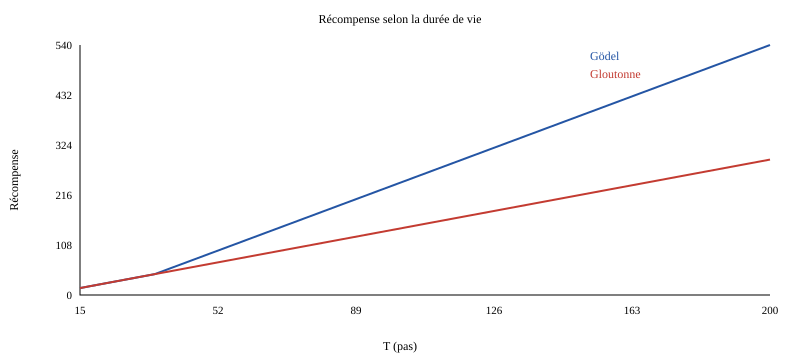

In [8]:
// Echantillon d'environnements du jeu savoir (q >= r+1 impose par rejet), graine fixee.
List<Env> Sample(int seed, int n, bool savoir) {
    var rng=new Random(seed); var list=new List<Env>();
    while(list.Count<n) { double r=1+rng.NextDouble(), q=1+3*rng.NextDouble(), w=(savoir?20:30)*rng.NextDouble(); if(!savoir || q>=r+1) list.Add(new Env(r,q,w)); }
    return list;
}
var sampleSavoir=Sample(42,2000,true);
// Pour chaque duree de vie T : plans Godel et glouton, ecart min et moyen sur 2000 environnements.
var lignes = new List<(int T,string G,string L,double ReelG,double ReelL,double Min,double Moy)>();
foreach(int T in Enumerable.Range(0,38).Select(i=>15+5*i)) {
    var g=Machine(new[]{"A","B"},"savoir",T,5);var l=Machine(new[]{"A","B"},"savoir",T,5,glouton:true);
    var d=sampleSavoir.Select(e=>Gain(g.Plan,T,e)-Gain(l.Plan,T,e)).ToArray();
    lignes.Add((T,g.Plan.Last().Policy,l.Plan.Last().Policy,Gain(g.Plan,T,reel),Gain(l.Plan,T,reel),d.Min(),d.Average()));
}
foreach(var z in lignes.Where(z=>new[]{15,20,25,30,35,40,60,100,150,200}.Contains(z.T))) Console.WriteLine($"T={z.T} : Gödel {z.G} {z.ReelG:F1}, glouton {z.L} {z.ReelL:F1}, min Δ {z.Min:F1}, moy Δ {z.Moy:F1}");
Console.WriteLine($"Premier T divergent : {lignes.First(z=>z.G!=z.L).T} ; T avec écart négatif échantillonné : {string.Join(",",lignes.Where(z=>z.Min<0).Select(z=>z.T))}");
// Figure : recompense des deux machines selon T -- la divergence apparait au-dela d'un seuil.
display(new SvgMarkup(SeriesSvg(lignes.Select(z=>(double)z.T).ToArray(),new[]{lignes.Select(z=>z.ReelG).ToArray(),lignes.Select(z=>z.ReelL).ToArray()},new[]{"Gödel","Gloutonne"},"Récompense selon la durée de vie","T (pas)","Récompense")));

Les machines peuvent diverger dès que B devient prouvable et rentable. Le minimum échantillonné peut être négatif : le théorème compare chaque décision à sa propre continuation, pas à la trajectoire d'une gloutonne. Les moyennes et minima dépendent du tirage fini. Dans cette exécution, la première divergence est à T=35 ; à T=200 les gains sont 540 et 292,5, et le minimum observé sur les 2 000 tirages est positif (123,0).

### Exercice 2 — Le théorème cible relâché
Complétez le comparateur symbolique $u_{switch} \geq u_{keep}$. Utilisez-le ensuite dans une copie de `Machine` et cherchez une durée de vie où les décisions diffèrent. Le garde prouve l'équivalence, y compris à l'égalité.

In [9]:
// Verificateur de l'exercice 2 : le comparateur doit etre equivalent a >= sur tous les reels.
bool VerifierComparateur(Func<Context,ArithExpr,ArithExpr,BoolExpr> comparer) {
 if(comparer==null)return false;
 using var ctx=new Context(); var a=ctx.MkRealConst("a");var b=ctx.MkRealConst("b");var expression=comparer(ctx,a,b);if(expression==null)return false;
 using var s=ctx.MkSolver();s.Assert(ctx.MkNot(ctx.MkIff(expression,ctx.MkGe(a,b))));return s.Check()==Status.UNSATISFIABLE;
}
// Exercice 2 : construire >= depuis les operations Z3 ; equivalence prouvee par contre-exemple.
Func<Context,ArithExpr,ArithExpr,BoolExpr> comparaisonRelachee = null; // TODO : remplacer > par >=
Console.WriteLine(comparaisonRelachee==null ? "Exercice 2 à compléter" : $"Comparateur valide : {VerifierComparateur(comparaisonRelachee)}");

Exercice 2 à compléter


## 5. Le prix de la prudence
Sous `base`, B peut perdre contre A. Sur 2 000 environnements tirés, comparez la moyenne et les pertes à la preuve universelle. On cherche aussi l'écart q ≥ r + e, par pas de 0,1, suffisant pour prouver B face à A, pour quatre bornes sur w.

In [10]:
// Sous le jeu base (sans savoir), la hierarchie s'inverse : B peut dominer A selon l'ecart q-r.
var planBase=Machine(new[]{"A","B"},"base",200,5);
Console.WriteLine($"Politique sous base : {planBase.Plan.Last().Policy}");
foreach(var a in planBase.Journal) Console.WriteLine($"  {a.Candidate} : {a.Proof.Verdict}, {a.Proof.Counterexample}");
// Distribution du gain B-A sur 2000 environnements : une preuve sur moyenne ne couvre pas chaque cas.
var envs=Sample(7,2000,false);var planA=new List<Segment>{new(0,"preuve"),new(5,"A")};var planB=new List<Segment>{new(0,"preuve"),new(10,"B")};
var diffs=envs.Select(e=>Gain(planB,200,e)-Gain(planA,200,e)).ToArray();
Console.WriteLine($"Moyennes A={envs.Average(e=>Gain(planA,200,e)):F1}, B={envs.Average(e=>Gain(planB,200,e)):F1}, fraction B<A={diffs.Count(d=>d<0)/20.0:F1}%, min={diffs.Min():F1}, max={diffs.Max():F1}");
// La meme comparaison, cette fois prouvee symboliquement : B a t=10 domine A a t=5 sous base.
var preuveCompare=Prouver("base",(ctx,e)=>ctx.MkGt(U(ctx,"B",190,e),U(ctx,"A",195,e)));
Console.WriteLine($"B à t=10 > A à t=5 : {preuveCompare.Verdict}, {preuveCompare.Counterexample}");
Console.WriteLine($"Réel : A={Gain(planA,200,reel)}, B={Gain(planB,200,reel)}, gain abandonné={Gain(planB,200,reel)-Gain(planA,200,reel)}");
// Balayage : pour chaque borne w, le premier ecart q-r qui rend "B > A" prouvable par Z3.
foreach(int maxw in new[]{30,20,10,0}) {
 double? minimum=null;
 for(int k=0;k<=40;k++) { double e=k/10.0; var pr=Prouver("base",(ctx,z)=>ctx.MkGt(U(ctx,"B",190,z),U(ctx,"A",195,z)),ecart:e,wMax:maxw); if(pr.Verdict=="PROUVE") {minimum=e;break;} }
 Console.WriteLine($"w <= {maxw} : premier écart prouvé = {minimum}");
}

Politique sous base : A


  A : PROUVE, 


Moyennes A=291.2, B=436.5, fraction B<A=21.9%, min=-207.3, max=536.8


B à t=10 > A à t=5 : REFUTE, r=3/2, q=3/2, w=1


Réel : A=292.5, B=540, gain abandonné=247.5


w <= 30 : premier écart prouvé = 0.5


w <= 20 : premier écart prouvé = 0.3


w <= 10 : premier écart prouvé = 0.2


w <= 0 : premier écart prouvé = 0.1


Le modèle sous `base` accepte A car il ne sait pas prouver B. Une moyenne supérieure ne garantit pas une amélioration dans chaque environnement ; l'échantillon quantifie ce risque sans remplacer la preuve. En environnement réel, le gain abandonné vaut 247,5. L'écart nécessaire dépend de la borne d'échauffement. Le tirage .NET donne 291,2 pour A et 436,5 pour B en moyenne ; B perd dans 21,9 % des environnements, avec une perte maximale de 207,3. Le premier écart prouvé vaut 0,5 si w ≤ 30, et 0,1 si w = 0.

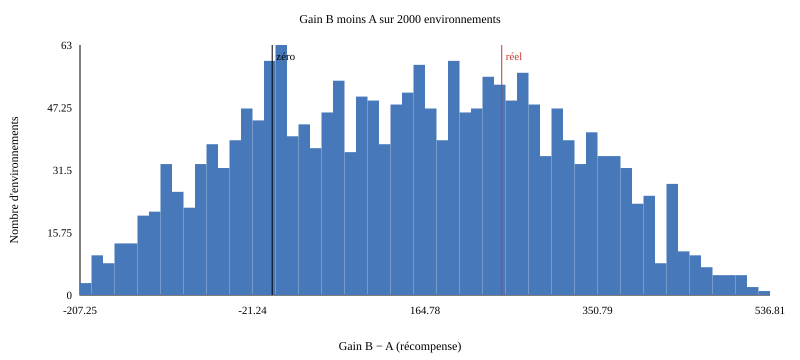

In [11]:
// Histogramme SVG du gain B-A : deux reperes verticaux, zero (noir) et cas reel (rouge).
string HistogramSvg(double[] values, int bins, double marker) {
    const int W=800,H=360,L=80,R=30,Top=45,Bot=65; double lo=values.Min(),hi=values.Max(); int[] counts=new int[bins];
    foreach(double v in values) counts[Math.Min(bins-1,(int)((v-lo)/(hi-lo)*bins))]++;
    int max=counts.Max(); double X(double v)=>L+(v-lo)/(hi-lo)*(W-L-R); double Y(double v)=>H-Bot-v/max*(H-Top-Bot);
    var b=new StringBuilder($"<svg xmlns='http://www.w3.org/2000/svg' width='{W}' height='{H}'><rect width='100%' height='100%' fill='white'/><text x='400' y='23' text-anchor='middle'>Gain B moins A sur 2000 environnements</text><path d='M {L} {Top} V {H-Bot} H {W-R}' stroke='black' fill='none'/>");
    for(int i=0;i<bins;i++) {double left=L+(W-L-R)*i/(double)bins, width=(W-L-R)/(double)bins; b.Append($"<rect x='{F(left)}' y='{F(Y(counts[i]))}' width='{F(width)}' height='{F(H-Bot-Y(counts[i]))}' fill='#4779ba'/>");}
    foreach(var mark in new[]{(0.0,"zéro","black"),(marker,"réel","#c33b31")}) b.Append($"<line x1='{F(X(mark.Item1))}' x2='{F(X(mark.Item1))}' y1='{Top}' y2='{H-Bot}' stroke='{mark.Item3}'/><text x='{F(X(mark.Item1)+4)}' y='{Top+15}' fill='{mark.Item3}' font-size='11'>{mark.Item2}</text>");
    for(int i=0;i<=4;i++) b.Append($"<text x='{F(X(lo+(hi-lo)*i/4))}' y='{H-Bot+19}' font-size='11' text-anchor='middle'>{F(lo+(hi-lo)*i/4)}</text><text x='{L-8}' y='{F(Y(max*i/4.0)+4)}' font-size='11' text-anchor='end'>{F(max*i/4.0)}</text>");
    b.Append($"<text x='400' y='{H-10}' text-anchor='middle'>Gain B − A (récompense)</text><text transform='translate(18,180) rotate(-90)' text-anchor='middle'>Nombre d'environnements</text></svg>");return b.ToString();
}
display(new SvgMarkup(HistogramSvg(diffs,60,Gain(planB,200,reel)-Gain(planA,200,reel))));

La partie à gauche de zéro rassemble les environnements où B perd. Même si B gagne en moyenne, ces cas suffisent à réfuter la domination universelle. Une utilité en espérance demanderait une loi explicite sur les environnements.

### Exercice 3 — Combien vaut un axiome ?
Calculez les récompenses réelles pour les 21 écarts de 0 à 2 par pas de 0,1 ; tracez la courbe et expliquez ce que signifie l'axiome faux e=2. Le garde rejette les valeurs non finies, les dimensions incorrectes et les résultats différents de la simulation.

In [12]:
// Verificateur de l'exercice 3 : rejoue la machine pour chaque ecart et compare au centieme.
bool VerifierValeurs(double[] valeurs) {
 if(valeurs==null || valeurs.Length!=21 || valeurs.Any(v=>!double.IsFinite(v)))return false;
 for(int k=0;k<21;k++) { var resultat=Machine(new[]{"A","B"},"base",200,5,ecart:k/10.0);if(Math.Abs(valeurs[k]-Gain(resultat.Plan,200,reel))>1e-8)return false; }
 return true;
}
// Exercice 3 : les 21 recompenses du plan pour e = 0, 0.1, ..., 2.0, dans l'ordre.
double[] valeurs = null; // TODO : 21 récompenses pour e=0, 0.1, ..., 2.0
Console.WriteLine(valeurs==null ? "Exercice 3 à compléter" : $"Courbe valide : {VerifierValeurs(valeurs)}");

Exercice 3 à compléter


## 6. Le temps de preuve se paie en vie
Chaque tentative dure 1 + ⌊budget/200⌋ pas. On conserve les onze budgets de 100 à 32 000 et mesure décision, verdicts et récompense. Le `rlimit` dépend de la version du moteur ; les frontières numériques peuvent donc différer.

budget   100 ; coût   1 ; calibrage à   2 ; gain  222.0 ; A:INCONNU B:INCONNU


budget   200 ; coût   2 ; calibrage à   4 ; gain  219.0 ; A:INCONNU B:INCONNU


budget   300 ; coût   2 ;         A à   2 ; gain  297.0 ; A:PROUVE


budget   400 ; coût   3 ;         A à   3 ; gain  295.5 ; A:PROUVE


budget   600 ; coût   4 ;         A à   4 ; gain  294.0 ; A:PROUVE


budget  1000 ; coût   6 ;         B à  12 ; gain  534.0 ; A:REFUTE B:PROUVE


budget  2000 ; coût  11 ;         B à  22 ; gain  504.0 ; A:REFUTE B:PROUVE


budget  4000 ; coût  21 ;         B à  42 ; gain  444.0 ; A:REFUTE B:PROUVE


budget  8000 ; coût  41 ;         B à  82 ; gain  324.0 ; A:REFUTE B:PROUVE


budget 16000 ; coût  81 ;         B à 162 ; gain   84.0 ; A:REFUTE B:PROUVE


budget 32000 ; coût 161 ;         A à 161 ; gain   58.5 ; A:PROUVE


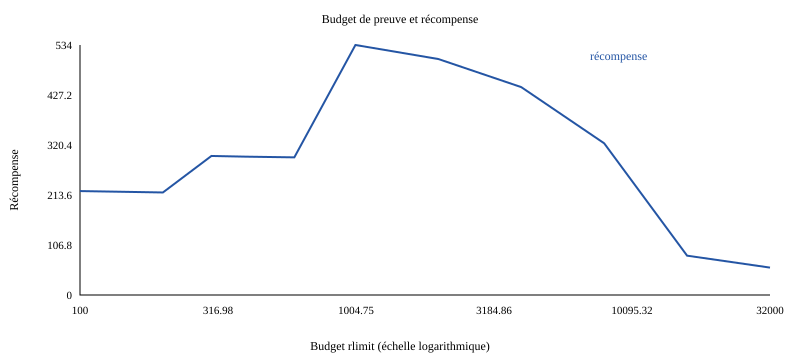

In [13]:
// Balayage du budget rlimit : trop faible, les preuves deviennent INCONNU et le plan degrade.
int[] budgets={100,200,300,400,600,1000,2000,4000,8000,16000,32000};
var resultats=new List<(int Budget,int Cout,string Pol,int Temps,double Gain,string Verdicts)>();
foreach(int b in budgets) {
 int cout=1+b/200; var run=Machine(new[]{"A","B"},"savoir",200,cout,(uint)b);
 resultats.Add((b,cout,run.Plan.Last().Policy,run.Plan.Last().Start,Gain(run.Plan,200,reel),string.Join(" ",run.Journal.Select(a=>$"{a.Candidate}:{a.Proof.Verdict}"))));
}
foreach(var z in resultats) Console.WriteLine($"budget {z.Budget,5} ; coût {z.Cout,3} ; {z.Pol,9} à {z.Temps,3} ; gain {z.Gain,6:F1} ; {z.Verdicts}");
// Figure (abscisse log) : la recompense plafonne puis chute quand le budget ne suffit plus.
display(new SvgMarkup(SeriesSvg(resultats.Select(z=>(double)z.Budget).ToArray(),new[]{resultats.Select(z=>z.Gain).ToArray()},new[]{"récompense"},"Budget de preuve et récompense","Budget rlimit (échelle logarithmique)","Récompense",true)));

Un budget insuffisant peut donner `UNKNOWN`. Un budget suffisant autorise la preuve, mais des tentatives trop longues consomment la vie disponible. Les valeurs observées ne sont pas une loi générale : elles dépendent des axiomes, de Z3 et de la conversion du budget en temps. Ici, 100 ne prouve rien (gain 222), 1 000 prouve B (534), et 32 000 n’autorise plus que A à t=161 (58,5).

## 7. Carte des décisions
On balaie 40 coûts de preuve et 38 durées de vie, soit 1 520 simulations, avec les mêmes axiomes `savoir`. Chaque case indique la politique finale.

initiale : 81 cases


A : 311 cases


B : 1128 cases


Coût 1 : A dès T=15, B dès T=25


Coût 5 : A dès T=15, B dès T=35


Coût 20 : A dès T=25, B dès T=65


Coût 40 : A dès T=45, B dès T=105


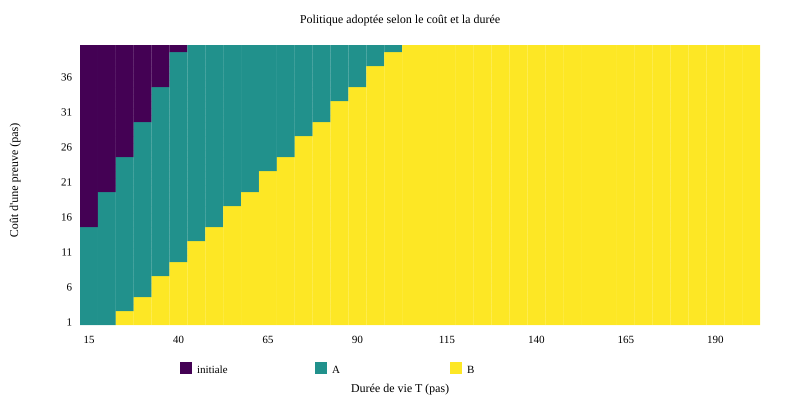

In [14]:
// Carte 40x38 : politique finale selon le cout d'une preuve et la duree de vie T.
var vies=Enumerable.Range(0,38).Select(i=>15+5*i).ToArray();var couts=Enumerable.Range(1,40).ToArray();
int[,] carte=new int[couts.Length,vies.Length];var code=new Dictionary<string,int>{{"calibrage",0},{"A",1},{"B",2}};
for(int i=0;i<couts.Length;i++) for(int j=0;j<vies.Length;j++) carte[i,j]=code[Machine(new[]{"A","B"},"savoir",vies[j],couts[i]).Plan.Last().Policy];
for(int k=0;k<3;k++) Console.WriteLine($"{new[]{"initiale","A","B"}[k]} : {carte.Cast<int>().Count(v=>v==k)} cases");
foreach(int cout in new[]{1,5,20,40}) { int i=cout-1; int? seuilA=null,seuilB=null;for(int j=0;j<vies.Length;j++){if(carte[i,j]==1 && !seuilA.HasValue)seuilA=vies[j];if(carte[i,j]==2 && !seuilB.HasValue)seuilB=vies[j];}Console.WriteLine($"Coût {cout} : A dès T={seuilA}, B dès T={seuilB}"); }
// Carte de chaleur SVG : calibrage (violet), A (turquoise), B (jaune) -- frontieres d'un coup.
string HeatSvg(int[,] map) {
 const int W=800,H=400,L=80,R=40,Top=45,Bot=75; double cw=(W-L-R)/(double)map.GetLength(1),ch=(H-Top-Bot)/(double)map.GetLength(0);string[] colors={"#440154","#21918c","#fde725"};
 var b=new StringBuilder($"<svg xmlns='http://www.w3.org/2000/svg' width='{W}' height='{H}'><rect width='100%' height='100%' fill='white'/><text x='400' y='23' text-anchor='middle'>Politique adoptée selon le coût et la durée</text>");
 for(int i=0;i<map.GetLength(0);i++)for(int j=0;j<map.GetLength(1);j++)b.Append($"<rect x='{F(L+j*cw)}' y='{F(H-Bot-(i+1)*ch)}' width='{F(cw+0.1)}' height='{F(ch+0.1)}' fill='{colors[map[i,j]]}'/>");
 for(int j=0;j<map.GetLength(1);j+=5)b.Append($"<text x='{F(L+(j+0.5)*cw)}' y='{H-Bot+18}' font-size='11' text-anchor='middle'>{vies[j]}</text>");
 for(int i=0;i<40;i+=5)b.Append($"<text x='{L-8}' y='{F(H-Bot-(i+0.5)*ch+4)}' font-size='11' text-anchor='end'>{couts[i]}</text>");
 b.Append($"<text x='400' y='{H-8}' text-anchor='middle'>Durée de vie T (pas)</text><text transform='translate(18,180) rotate(-90)' text-anchor='middle'>Coût d'une preuve (pas)</text>");
 for(int k=0;k<3;k++)b.Append($"<rect x='{180+k*135}' y='{H-38}' width='12' height='12' fill='{colors[k]}'/><text x='{197+k*135}' y='{H-27}' font-size='11'>{new[]{"initiale","A","B"}[k]}</text>");return b.Append("</svg>").ToString();
}
display(new SvgMarkup(HeatSvg(carte)));

La carte distingue les régions où aucune preuve n'arrive à temps, où A est adopté et où B est adopté. La frontière se déplace vers les vies longues quand le coût des tentatives augmente : ce coût entre directement dans l'utilité. Les 1 520 cases se répartissent en 81 initiales, 311 A et 1 128 B ; B apparaît dès T=25 au coût 1, et dès T=105 au coût 40.

## 8. Exercices
Les exercices répartis ci-dessus portent sur le candidat mixte, le théorème relâché et la valeur d'un axiome.

## Limites du jouet
Les réécritures candidates sont données, et le coût du calcul anticipé de la continuation n'est pas facturé. Les preuves portent sur chaque environnement admissible, ce qui est plus fort qu'une comparaison d'espérances sous une loi donnée. Le produit q × (D−w) rend l'arithmétique non linéaire ; une limite de ressources peut produire `UNKNOWN`.

## À retenir
| Question | Réponse |
|---|---|
| Quand basculer ? | Quand l'amélioration sur la continuation est prouvée. |
| Que coûte la prudence ? | Une amélioration réelle peut être refusée faute d'axiomes suffisants. |
| Où entre le temps de preuve ? | Dans l'utilité et la durée de vie restante. |

## Vérifiez votre compréhension
Pourquoi un contre-exemple interdit-il la bascule ?
<details><summary>Réponse</summary>Il montre un environnement admissible où l'inégalité exigée n'est pas vraie.</details>

## Pour aller plus loin
Consulter [le source Python de ce chapitre](Z3-20-Machine-de-Goedel-Python.ipynb) pour le contexte historique et [Z3-05 Quantificateurs et preuves](Z3-05-Quantifiers-Proofs-Python.ipynb) pour la mécanique de réfutation.